# PS1: Basic CNN for handwritten digit classification (MNIST)

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow import keras
from tensorflow.keras import layers

EPOCHS = 5

Train: (60000, 28, 28, 1) Test: (10000, 28, 28, 1)


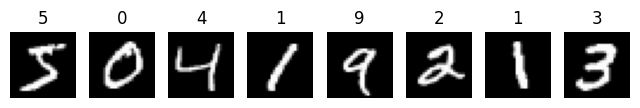

In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()
x_train = x_train[..., None] / 255.0
x_test = x_test[..., None] / 255.0
print("Train:", x_train.shape, "Test:", x_test.shape)

plt.figure(figsize=(8, 2))
for i in range(8):
    plt.subplot(1, 8, i + 1)
    plt.imshow(x_train[i].squeeze(), cmap="gray")
    plt.title(y_train[i])
    plt.axis("off")
plt.show()

In [3]:
model = keras.Sequential([
    layers.Input((28, 28, 1)),
    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dropout(0.3),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax"),
])
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [4]:
history = model.fit(x_train, y_train, epochs=EPOCHS, batch_size=128, validation_split=0.1, verbose=2)

Epoch 1/5


422/422 - 6s - 14ms/step - accuracy: 0.9257 - loss: 0.2421 - val_accuracy: 0.9825 - val_loss: 0.0597


Epoch 2/5


422/422 - 5s - 12ms/step - accuracy: 0.9774 - loss: 0.0739 - val_accuracy: 0.9877 - val_loss: 0.0436


Epoch 3/5


422/422 - 5s - 12ms/step - accuracy: 0.9840 - loss: 0.0518 - val_accuracy: 0.9890 - val_loss: 0.0377


Epoch 4/5


422/422 - 5s - 12ms/step - accuracy: 0.9869 - loss: 0.0426 - val_accuracy: 0.9897 - val_loss: 0.0352


Epoch 5/5


422/422 - 5s - 12ms/step - accuracy: 0.9894 - loss: 0.0334 - val_accuracy: 0.9913 - val_loss: 0.0338


Test accuracy: 0.9920   Test loss: 0.0246


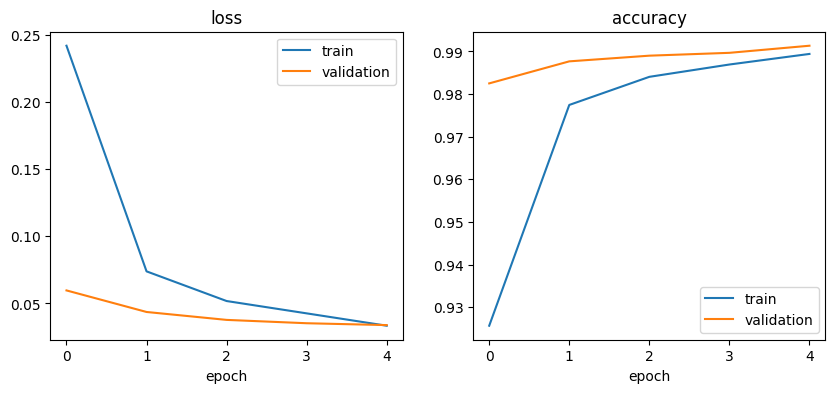

In [5]:
loss, acc = model.evaluate(x_test, y_test, verbose=0)
print(f"Test accuracy: {acc:.4f}   Test loss: {loss:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for i, metric in enumerate(["loss", "accuracy"]):
    ax[i].plot(history.history[metric], label="train")
    ax[i].plot(history.history["val_" + metric], label="validation")
    ax[i].set_title(metric)
    ax[i].set_xlabel("epoch")
    ax[i].legend()
plt.show()

              precision    recall  f1-score   support

           0     0.9939    0.9959    0.9949       980
           1     0.9965    0.9982    0.9974      1135
           2     0.9903    0.9932    0.9918      1032
           3     0.9911    0.9931    0.9921      1010
           4     0.9939    0.9919    0.9929       982
           5     0.9910    0.9854    0.9882       892
           6     0.9927    0.9906    0.9916       958
           7     0.9941    0.9864    0.9902      1028
           8     0.9867    0.9928    0.9898       974
           9     0.9891    0.9911    0.9901      1009

    accuracy                         0.9920     10000
   macro avg     0.9919    0.9919    0.9919     10000
weighted avg     0.9920    0.9920    0.9920     10000



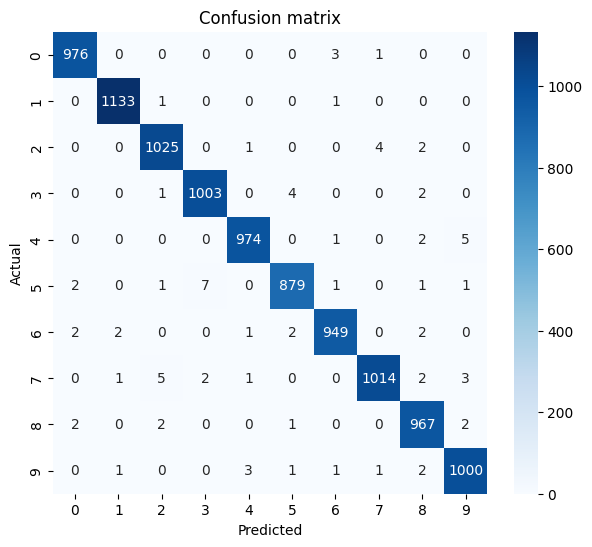

In [6]:
y_pred = model.predict(x_test, verbose=0).argmax(axis=1)
print(classification_report(y_test, y_pred, digits=4))

plt.figure(figsize=(7, 6))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion matrix")
plt.show()

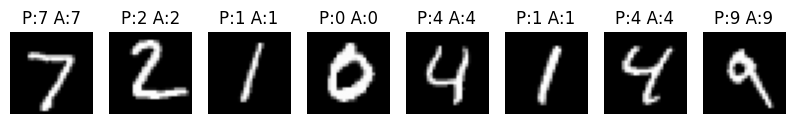

In [7]:
plt.figure(figsize=(10, 2))
for i in range(8):
    plt.subplot(1, 8, i + 1)
    plt.imshow(x_test[i].squeeze(), cmap="gray")
    plt.title(f"P:{y_pred[i]} A:{y_test[i]}")
    plt.axis("off")
plt.show()